In [88]:
import pandas as pd

unctad_df = pd.read_csv('UNCTAD_data.csv', na_values=[".."])
wdi_df = pd.read_csv('WDI_data.csv')
unctad_df['Time'] = pd.to_datetime(unctad_df['Time']).dt.year
wdi_df['Time'] = pd.to_datetime(wdi_df['Time']).dt.year

In [89]:
# Check duplicates in WDI data
wdi_dups = wdi_df.duplicated(subset=['Country Name', 'Time']).sum()
print(f"Duplicate rows in WDI keys: {wdi_dups}")

# Check duplicates in UNCTAD data
unctad_dups = unctad_df.duplicated(subset=['Reporter', 'Time']).sum()
print(f"Duplicate rows in UNCTAD keys: {unctad_dups}")

Duplicate rows in WDI keys: 10791
Duplicate rows in UNCTAD keys: 48591


In [90]:
wdi_df = wdi_df.drop_duplicates(subset=['Country Name', 'Time'])

In [91]:
unctad_df['Reporter'] = unctad_df['Reporter'].replace({'Vietnam': 'Viet Nam'})

In [92]:

data = pd.merge(
    unctad_df,
    wdi_df,
    left_on=['Reporter', 'Time'],
    right_on=['Country Name', 'Time'],
    how='left'
)

In [93]:
print("Before:", unctad_df.shape)
print("After:", data.shape)

Before: (48600, 11)
After: (48600, 17)


In [94]:
print(data.notnull().sum())

Reporter                 48600
Reporter Code            48600
Partner Name             48600
Partner Code             48600
Tariff Indicator Name    48600
Tariff Indicator Code    48600
Product                  48600
Product Code             48600
Time                     48600
Time Code_x              48600
Value_x                  33282
Country Name             48600
Country Code             48600
Series Name              48600
Series Code              48600
Time Code_y              48600
Value_y                  48600
dtype: int64


In [95]:
unmatched_reporters = data[data['Country Name'].isna()]['Reporter'].unique()
print("Reporters with missing WDI matches:")
print(unmatched_reporters)

Reporters with missing WDI matches:
<ArrowStringArray>
[]
Length: 0, dtype: str


In [96]:
data.columns

Index(['Reporter', 'Reporter Code', 'Partner Name', 'Partner Code',
       'Tariff Indicator Name', 'Tariff Indicator Code', 'Product',
       'Product Code', 'Time', 'Time Code_x', 'Value_x', 'Country Name',
       'Country Code', 'Series Name', 'Series Code', 'Time Code_y', 'Value_y'],
      dtype='str')

In [97]:
data['Tariff Indicator Name'].unique()

<ArrowStringArray>
['A.SimpleAverage (%)', 'B.Weighted Average']
Length: 2, dtype: str

In [98]:
data['Partner Name'].unique()

<ArrowStringArray>
[      'China',   'Indonesia',       'Japan', 'Korea, Rep.',    'Malaysia',
 'Philippines',   'Singapore',     'Vietnam',  'Bangladesh',      ' World']
Length: 10, dtype: str

In [99]:
data['Product'].unique()

<ArrowStringArray>
[                                                                                                                                                                                 '52 -- COTTON',
                                                                                                                    '54 -- MAN-MADE FILAMENTS; STRIP AND THE LIKE OF MAN-MADE TEXTILE MATERIALS',
                                                                                                                                                                  '55 -- MAN-MADE STAPLE FIBRES',
                                                                                                                                                            '60 -- KNITTED OR CROCHETED FABRICS',
                                                                                                                      '61 -- ARTICLES OF APPAREL AND CLOTHING ACCESSORIES, KNITTED OR CROCHETED',
           

In [100]:
data['Reporter'].unique()

<ArrowStringArray>
[ 'Bangladesh',       'China',   'Indonesia', 'Korea, Rep.',       'Japan',
    'Malaysia', 'Philippines',   'Singapore',    'Viet Nam']
Length: 9, dtype: str

In [101]:
bd_trade = data[data['Reporter'] == 'Bangladesh'][['Time', 'Partner Name', 'Product', 'Value_x', 'Tariff Indicator Name']].describe(include='all')

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

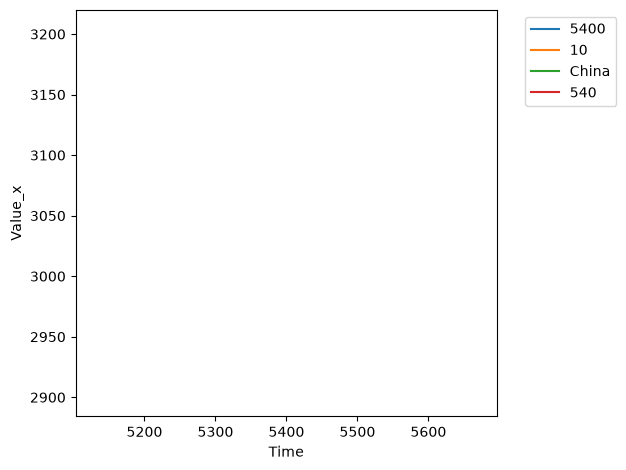

In [106]:
# Find the top 5 partners by total trade value
top_partners = bd_trade.groupby('Partner Name')['Value_x'].sum().nlargest(5).index

# Filter the dataframe
filtered_trade = bd_trade[bd_trade['Partner Name'].isin(top_partners)]

# Plot only the top partners
sns.lineplot(data=filtered_trade, x='Time', y='Value_x', hue='Partner Name')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Move legend outside the plot
plt.tight_layout()
plt.show()

In [111]:
# Group by Partner Name, sum their total trade value, and get the top 5
top_5_partners = (
    bd_trade.groupby('Partner Name')['Value_x']
    .sum()
    .nlargest(5)
)

print("Top 5 Trading Partners of Bangladesh:")
print(top_5_partners)

Top 5 Trading Partners of Bangladesh:
Partner Name
5400     3052.0
10          0.0
540         0.0
China       0.0
Name: Value_x, dtype: float64


In [110]:
top_partners

Index([5400, 10, 540, 'China'], dtype='object', name='Partner Name')

In [113]:
# 1. Check what unique values actually look like in Partner Name and Time
print("Sample Partner Names:", bd_trade['Partner Name'].unique()[:10])
print("Sample Times:", bd_trade['Time'].unique())

# 2. If 'Time' is stored as something weird, let's coerce it to numeric/year
bd_trade['Time'] = pd.to_numeric(bd_trade['Time'], errors='coerce')

# 3. If you have a separate 'Partner Code' and want actual text names, 
# make sure you didn't accidentally group by a code column. 
# Let's find the top 5 properly by filtering out any numeric-only artifacts if needed:
top_partners = bd_trade.groupby('Partner Name')['Value_x'].sum().nlargest(5).index
print("Real top partners:", top_partners)

Sample Partner Names: [np.int64(5400) 10 'China' np.int64(540) nan]
Sample Times: [5400.   nan 1970.    0.]
Real top partners: Index([5400, 10, 540, 'China'], dtype='object', name='Partner Name')


Actual Top 5 Partners: Index([], dtype='object', name='Partner Name')


C:\Users\moham\AppData\Local\Temp\ipykernel_12428\3396968911.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


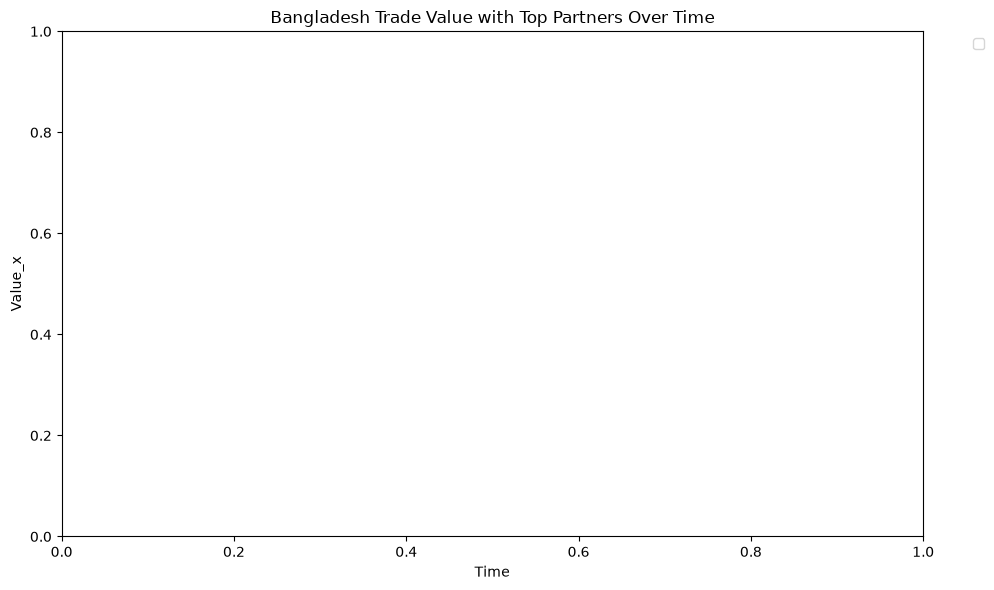

In [114]:
# 1. Keep only rows where Partner Name is an actual string (country name) and not a numeric code
bd_trade_clean = bd_trade[bd_trade['Partner Name'].apply(lambda x: isinstance(x, str))].copy()

# 2. Filter out invalid/placeholder years (like 0 or missing values) and keep real calendar years (e.g., >= 1980)
bd_trade_clean = bd_trade_clean[(bd_trade_clean['Time'] >= 1980) & (bd_trade_clean['Time'] <= 2026)]

# 3. Find the actual top 5 real trade partners on the cleaned data
top_5 = bd_trade_clean.groupby('Partner Name')['Value_x'].sum().nlargest(5).index
print("Actual Top 5 Partners:", top_5)

# 4. Filter for just those top 5 and plot properly
final_plot_data = bd_trade_clean[bd_trade_clean['Partner Name'].isin(top_5)]

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.lineplot(data=final_plot_data, x='Time', y='Value_x', hue='Partner Name')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Bangladesh Trade Value with Top Partners Over Time")
plt.tight_layout()
plt.show()